# Making Gradient Descent Fast: Loops vs Vectorization

*By Shikha Pallavi*

The same gradient descent can run in seconds or in milliseconds, depending on how you write it. Here we take the algorithm from Part 3, write it three ways, check that all three agree, and **measure** the speed.

> ## 📖 Read the full series: [Machine Learning Basics](https://shikhapallavi123.github.io/ml-basics/)
> This notebook is the hands-on companion to **Part 4**. Read the post for the explanation, then run the code here.
> [Part 1: Foundations](https://shikhapallavi123.github.io/ml-basics/part-1-foundations.html) · [Part 2: Supervised Learning](https://shikhapallavi123.github.io/ml-basics/part-2-supervised-learning.html) · [Part 3: Linear Regression](https://shikhapallavi123.github.io/ml-basics/part-3-linear-regression.html) · [Part 4: Fast Gradient Descent](https://shikhapallavi123.github.io/ml-basics/part-4-fast-gradient-descent.html)

**What you'll see**
1. A pure Python loop, a NumPy version and a matrix version of the same update
2. A correctness check, so speed never costs accuracy
3. Timings from 1,000 to 1,000,000 samples, plotted
4. Why the gap exists, and how to profile before optimizing

## 1. The problem

We fit `h(x) = θ0 + θ1·x` by gradient descent, exactly as in Part 3. The update uses the average error and the average error weighted by x:

```
θ0 := θ0 − α · mean(err)
θ1 := θ1 − α · mean(err · x)        where err = h(x) − y
```

The math never changes. Only the way we write it does.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)

def make_data(n):
    x = rng.uniform(0, 1, n)
    y = 4.0 + 3.0 * x + rng.normal(0, 0.1, n)   # true theta0 = 4, theta1 = 3
    return x, y

ALPHA, STEPS = 0.5, 200
print("numpy", np.__version__)

numpy 2.5.3


## 2. Version A: a plain Python loop

One pass over the data per step, one sample at a time. This is how many people first write it, and it is a fair baseline: we use plain Python lists, which are faster for element by element work than indexing a NumPy array in a loop.

In [2]:
def gd_loop(x, y, alpha=ALPHA, steps=STEPS):
    n = len(x)
    t0 = t1 = 0.0
    for _ in range(steps):
        g0 = g1 = 0.0
        for i in range(n):
            err = t0 + t1 * x[i] - y[i]
            g0 += err
            g1 += err * x[i]
        t0 -= alpha * g0 / n
        t1 -= alpha * g1 / n
    return t0, t1

## 3. Version B: vectorized NumPy

Same update, but the loop over samples moves into NumPy, which runs it in compiled code.

In [3]:
def gd_numpy(x, y, alpha=ALPHA, steps=STEPS):
    t0 = t1 = 0.0
    for _ in range(steps):
        err = t0 + t1 * x - y
        t0 -= alpha * err.mean()
        t1 -= alpha * (err * x).mean()
    return t0, t1

## 4. Version C: matrix form

Stack the features into a matrix `X` with a column of ones. The whole gradient becomes one line, `Xᵀ(Xθ − y) / n`, and it scales to many features with no extra code.

In [4]:
def gd_matrix(x, y, alpha=ALPHA, steps=STEPS):
    n = len(x)
    X = np.column_stack([np.ones(n), x])
    theta = np.zeros(2)
    for _ in range(steps):
        theta -= alpha * (X.T @ (X @ theta - y)) / n
    return tuple(theta)

## 5. Do they agree?

A fast wrong answer is useless, so check first. All three should land on the same parameters (about 4 and 3).

In [5]:
x, y = make_data(2000)
xl, yl = x.tolist(), y.tolist()

a = gd_loop(xl, yl)
b = gd_numpy(x, y)
c = gd_matrix(x, y)
for name, r in [("loop", a), ("numpy", b), ("matrix", c)]:
    print(f"{name:<7} theta0 = {r[0]:.6f}   theta1 = {r[1]:.6f}")

assert np.allclose(a, b) and np.allclose(b, c)
print("All three versions agree.")

loop    theta0 = 4.001178   theta1 = 2.997182
numpy   theta0 = 4.001178   theta1 = 2.997182
matrix  theta0 = 4.001178   theta1 = 2.997182
All three versions agree.


## 6. Measure the speed

We time each version at several data sizes and keep the **best of a few runs**, which reduces noise from other processes. The pure Python loop stops at 100,000 samples because it becomes too slow to wait for.

In [6]:
def best_time(fn, args, repeats):
    best = float("inf")
    for _ in range(repeats):
        t = time.perf_counter()
        fn(*args)
        best = min(best, time.perf_counter() - t)
    return best

sizes = [1_000, 10_000, 100_000, 1_000_000]
rows = []
for n in sizes:
    x, y = make_data(n)
    xl, yl = x.tolist(), y.tolist()
    t_loop = best_time(gd_loop, (xl, yl), 1) if n <= 100_000 else None
    t_np = best_time(gd_numpy, (x, y), 3)
    t_mx = best_time(gd_matrix, (x, y), 3)
    rows.append((n, t_loop, t_np, t_mx))

print(f"{'samples':>10} {'loop (s)':>10} {'numpy (s)':>10} {'matrix (s)':>11} {'loop/numpy':>11}")
for n, tl, tn, tm in rows:
    ls = f"{tl:.3f}" if tl is not None else "-"
    sp = f"{tl / tn:.0f}x" if tl is not None else "-"
    print(f"{n:>10,} {ls:>10} {tn:>10.4f} {tm:>11.4f} {sp:>11}")

   samples   loop (s)  numpy (s)  matrix (s)  loop/numpy
     1,000      0.016     0.0015      0.0010         10x
    10,000      0.143     0.0049      0.0043         29x
   100,000      1.480     0.0693      0.0831         21x
 1,000,000          -     1.1537      0.6859           -


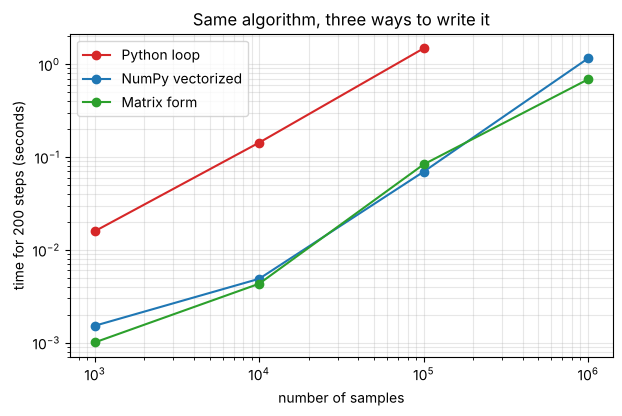

In [7]:
ns = [r[0] for r in rows]
plt.figure(figsize=(7, 4.2))
loop_pts = [(r[0], r[1]) for r in rows if r[1] is not None]
plt.loglog(*zip(*loop_pts), "o-", color="tab:red", label="Python loop")
plt.loglog(ns, [r[2] for r in rows], "o-", color="tab:blue", label="NumPy vectorized")
plt.loglog(ns, [r[3] for r in rows], "o-", color="tab:green", label="Matrix form")
plt.xlabel("number of samples")
plt.ylabel("time for 200 steps (seconds)")
plt.title("Same algorithm, three ways to write it")
plt.grid(alpha=0.3, which="both")
plt.legend()
plt.show()

## 7. Why is the loop so much slower?

- **Interpreter overhead.** Every `x[i]`, multiply and add in a Python loop goes through the interpreter, which does extra work on each one.
- **Compiled inner loops.** NumPy runs the same arithmetic in compiled code over a contiguous block of memory, often using the CPU's vector instructions.
- **Fewer passes.** The matrix form hands the whole gradient to optimized linear algebra routines.

You can see the effect on a single operation:

In [8]:
x, y = make_data(1_000_000)
xl = x.tolist()

t = time.perf_counter(); s = 0.0
for v in xl:
    s += v * v
t_py = time.perf_counter() - t

t = time.perf_counter(); s2 = float(x @ x)
t_np = time.perf_counter() - t

print(f"sum of squares of 1,000,000 numbers")
print(f"  Python loop: {t_py * 1000:.1f} ms")
print(f"  NumPy:       {t_np * 1000:.2f} ms")

sum of squares of 1,000,000 numbers
  Python loop: 86.1 ms
  NumPy:       1.53 ms


## 8. Profile before you optimize

Never guess where time goes. Python's built-in profiler shows it directly:

In [9]:
import cProfile, pstats, io

x, y = make_data(200_000)
pr = cProfile.Profile()
pr.enable()
gd_numpy(x, y, steps=50)
pr.disable()

buf = io.StringIO()
pstats.Stats(pr, stream=buf).sort_stats("cumulative").print_stats(6)
print("\n".join(buf.getvalue().splitlines()[:16]))

         1043 function calls in 0.054 seconds

   Ordered by: cumulative time
   List reduced from 29 to 6 due to restriction <6>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        2    0.000    0.000    0.054    0.027 /usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py:3786(run_code)
        2    0.000    0.000    0.054    0.027 {built-in method builtins.exec}
        1    0.041    0.041    0.053    0.053 /tmp/ipykernel_307/3682140284.py:1(gd_numpy)
      100    0.000    0.000    0.012    0.000 {method 'mean' of 'numpy.ndarray' objects}
      100    0.001    0.000    0.012    0.000 /usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:115(_mean)
      100    0.009    0.000    0.009    0.000 {method 'reduce' of 'numpy.ufunc' objects}




## Key takeaways

- The **algorithm** is the same in all three versions. The **implementation** decides the speed.
- **Vectorize** loops over data. Move the work into compiled code.
- **Check correctness** before you compare speed.
- **Measure**, with best-of-several timings and a profiler, instead of guessing.
- Timings change from machine to machine. Re-run the cells here and compare your own numbers.

## 📖 Continue the series
**[Read all of Machine Learning Basics →](https://shikhapallavi123.github.io/ml-basics/)**
[Part 1: Foundations](https://shikhapallavi123.github.io/ml-basics/part-1-foundations.html) · [Part 2: Supervised Learning](https://shikhapallavi123.github.io/ml-basics/part-2-supervised-learning.html) · [Part 3: Linear Regression](https://shikhapallavi123.github.io/ml-basics/part-3-linear-regression.html) · [Part 4: Fast Gradient Descent](https://shikhapallavi123.github.io/ml-basics/part-4-fast-gradient-descent.html)

---
*© 2026 Shikha Pallavi. Shared under the Apache 2.0 license. You are welcome to reuse the code. Please credit the author and link back to the Machine Learning Basics series.*